# Comprensión de los datos y EDA — Predicción de pago a tiempo de créditos

## 1. Comprensión del negocio
La base corresponde a **créditos otorgados** por una entidad financiera entre nov-2024 y abr-2026. Cada fila es un crédito y combina información del préstamo (monto, plazo, cuota), del cliente (edad, tipo laboral, salario) y de su historial en centrales de riesgo (puntaje Datacrédito, saldos, créditos vigentes, consultas).

**Objetivo del modelo (supervisado, clasificación binaria):** predecir `Pago_atiempo` (1 = el cliente pagó a tiempo, 0 = no pagó a tiempo).

**Valor para el negocio:** identificar *antes* de desembolsar qué créditos tienen mayor probabilidad de incumplimiento, para ajustar aprobación, monto, plazo o tasa y reducir pérdidas por cartera vencida.

**Pregunta clave:** el costo de equivocarse no es simétrico. Aprobar a quien no paga (falso positivo de "buen pagador") cuesta más que rechazar a uno que sí pagaría. Esto condiciona la métrica que se elegirá más adelante (recall/precision de la clase 0, PR-AUC, no solo accuracy).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RUTA_CSV = Path("..") / "Base_de_datos.csv"
df = pd.read_csv(RUTA_CSV)
TARGET = "Pago_atiempo"
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 10,763 | Columnas: 23


,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,"1,852,560.00",12,32,Empleado,3500000,1000000,128650,95.23,795.00,0,2,0.00,0.00,NaN,NaN,0,0,0,"916,148.00",Creciente,1
1,4,2025-01-09 11:18:48,"3,181,080.00",6,34,Empleado,5000000,2000000,441817,95.23,796.00,0,7,0.00,0.00,NaN,NaN,0,0,0,"4,473,774.00",Creciente,1
2,9,2024-12-26 18:52:57,"670,200.00",5,34,Independiente,5000000,2000000,108632,95.23,727.00,5,0,0.00,"274,561.00","274,561.00",NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,"506,806.80",2,25,Independiente,3000000,900000,199684,95.23,864.00,8,1,0.00,"27,564.00","27,564.00",NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,"999,780.00",10,26,Empleado,2000000,600000,92509,95.23,771.00,0,3,0.00,0.00,NaN,NaN,0,0,0,"61,000.00",Creciente,1


## 2. Exploración inicial de los datos
### 2.1 Descripción general y tipos de datos cargados

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  float64
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  float64
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

In [3]:
print("Duplicados exactos:", df.duplicated().sum())
print("Rango de fechas:", df['fecha_prestamo'].min(), "->", df['fecha_prestamo'].max())

Duplicados exactos: 0
Rango de fechas: 2024-11-26 09:17:04 -> 2026-04-26 18:43:52


### 2.2 Caracterización de las variables

| Variable | Descripción | Tipo estadístico |
|---|---|---|
| `tipo_credito` | Código del producto de crédito (4, 9, 10, 6, 7, 68) | Categórica **nominal** politómica (es un código, no una cantidad) |
| `fecha_prestamo` | Fecha y hora del desembolso | Fecha |
| `capital_prestado` | Monto desembolsado | Numérica continua |
| `plazo_meses` | Plazo del crédito en meses | Numérica discreta |
| `edad_cliente` | Edad del cliente | Numérica discreta |
| `tipo_laboral` | Empleado / Independiente | Categórica **nominal dicotómica** |
| `salario_cliente` | Ingreso declarado | Numérica continua |
| `total_otros_prestamos` | Valor de otros préstamos del cliente | Numérica continua |
| `cuota_pactada` | Cuota mensual pactada | Numérica continua |
| `puntaje` | Puntaje interno (ver alerta de fuga de datos en 4.4) | Numérica continua |
| `puntaje_datacredito` | Puntaje de la central de riesgo (rango típico 150–950) | Numérica discreta |
| `cant_creditosvigentes` | Créditos vigentes del cliente | Numérica discreta (conteo) |
| `huella_consulta` | Número de consultas a centrales de riesgo | Numérica discreta (conteo) |
| `saldo_mora`, `saldo_total`, `saldo_principal`, `saldo_mora_codeudor` | Saldos reportados (mora, total, capital, mora del codeudor) | Numéricas continuas |
| `creditos_sectorFinanciero/Cooperativo/Real` | Créditos del cliente por sector | Numéricas discretas (conteo) |
| `promedio_ingresos_datacredito` | Ingreso promedio reportado por la central | Numérica continua |
| `tendencia_ingresos` | Creciente / Estable / Decreciente | Categórica **ordinal** |
| `Pago_atiempo` | **Variable objetivo** (1 = pagó a tiempo, 0 = no) | Categórica **dicotómica** |

### 2.3 Revisión de nulos

In [4]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "% nulos": df.isna().mean() * 100,
})
nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,% nulos
tendencia_ingresos,2932,27.24
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06


**Lectura:**
- `promedio_ingresos_datacredito` y `tendencia_ingresos` tienen ~27% de nulos: probablemente son clientes **sin historial de ingresos en la central**. Es información faltante *con significado* (no aleatoria), así que conviene crear un indicador de "sin dato" en vez de solo imputar.
- `saldo_principal` (~4%), `saldo_mora_codeudor` (~5%), `saldo_mora` y `saldo_total` (~1.4%) tienen pocos nulos. En `saldo_mora_codeudor` puede significar "no tiene codeudor".
- `puntaje_datacredito` solo tiene 6 nulos: se pueden imputar con la mediana.

### 2.4 Unificar la representación de los valores nulos

In [5]:
# tendencia_ingresos debería contener solo 3 categorías, pero trae valores numéricos
print(df["tendencia_ingresos"].value_counts(dropna=False).head(8))
validas = ["Creciente", "Estable", "Decreciente"]
invalidos = ~df["tendencia_ingresos"].isin(validas) & df["tendencia_ingresos"].notna()
print("\nValores no válidos en tendencia_ingresos:", invalidos.sum())

tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
Name: count, dtype: int64

Valores no válidos en tendencia_ingresos: 58


`tendencia_ingresos` mezcla las 3 categorías esperadas con **números sueltos** (0, 8315, 1000000, -28589…): parecen valores de otra columna que se colaron por un error de carga. Como no son categorías reales, se convierten a **NaN**, igual que los vacíos, para que todos los nulos se representen de una sola forma.

In [6]:
df_limpio = df.copy()

# 1) Texto no válido -> NaN
df_limpio.loc[invalidos, "tendencia_ingresos"] = np.nan

# 2) Cadenas vacías o espacios -> NaN en columnas de texto
for col in df_limpio.select_dtypes(include=["object", "string"]).columns:
    df_limpio[col] = df_limpio[col].replace(r"^\s*$", np.nan, regex=True)

# 3) Valores imposibles en puntaje_datacredito (<= 0) -> NaN (el puntaje real va de 150 a 950 aprox.)
print("puntaje_datacredito <= 0:", (df_limpio["puntaje_datacredito"] <= 0).sum())
df_limpio.loc[df_limpio["puntaje_datacredito"] <= 0, "puntaje_datacredito"] = np.nan

df_limpio["tendencia_ingresos"].value_counts(dropna=False)

puntaje_datacredito <= 0: 146


tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64

### 2.5 Conversión a tipos correctos

In [7]:
df_limpio["fecha_prestamo"] = pd.to_datetime(df_limpio["fecha_prestamo"])
df_limpio["tipo_credito"] = df_limpio["tipo_credito"].astype("category")        # es un código nominal
df_limpio["tipo_laboral"] = df_limpio["tipo_laboral"].astype("category")
df_limpio["tendencia_ingresos"] = pd.Categorical(
    df_limpio["tendencia_ingresos"],
    categories=["Decreciente", "Estable", "Creciente"], ordered=True,          # ordinal
)
df_limpio[TARGET] = df_limpio[TARGET].astype("int8")                            # dicotómica 0/1

df_limpio.dtypes

tipo_credito                           category
fecha_prestamo                   datetime64[us]
capital_prestado                        float64
plazo_meses                               int64
edad_cliente                              int64
tipo_laboral                           category
salario_cliente                           int64
total_otros_prestamos                     int64
cuota_pactada                             int64
puntaje                                 float64
puntaje_datacredito                     float64
cant_creditosvigentes                     int64
huella_consulta                           int64
saldo_mora                              float64
saldo_total                             float64
saldo_principal                         float64
saldo_mora_codeudor                     float64
creditos_sectorFinanciero                 int64
creditos_sectorCooperativo                int64
creditos_sectorReal                       int64
promedio_ingresos_datacredito           

### 2.6 Eliminación de variables irrelevantes y revisión de coherencia

In [8]:
# Variables casi constantes (poca información)
casi_const = {c: df_limpio[c].value_counts(normalize=True, dropna=False).iloc[0]
              for c in df_limpio.columns if c != "fecha_prestamo"}
pd.Series(casi_const).sort_values(ascending=False).head(8).rename("% del valor más frecuente")

saldo_mora                   0.98
Pago_atiempo                 0.95
saldo_mora_codeudor          0.94
puntaje                      0.87
creditos_sectorCooperativo   0.82
tipo_credito                 0.72
tipo_laboral                 0.63
tendencia_ingresos           0.49
Name: % del valor más frecuente, dtype: float64

In [9]:
# Coherencia: saldo_principal no debería superar saldo_total; salarios, edades y deudas extremas
checks = {
    "saldo_principal > saldo_total": (df_limpio["saldo_principal"] > df_limpio["saldo_total"]).sum(),
    "salario_cliente == 0": (df_limpio["salario_cliente"] == 0).sum(),
    "salario_cliente > 100 millones": (df_limpio["salario_cliente"] > 100e6).sum(),
    "edad_cliente > 90": (df_limpio["edad_cliente"] > 90).sum(),
    "edad_cliente < 21": (df_limpio["edad_cliente"] < 21).sum(),
    "total_otros_prestamos > 1.000 millones": (df_limpio["total_otros_prestamos"] > 1e9).sum(),
    "plazo_meses > 48": (df_limpio["plazo_meses"] > 48).sum(),
}
pd.Series(checks, name="registros")

saldo_principal > saldo_total               0
salario_cliente == 0                       24
salario_cliente > 100 millones             74
edad_cliente > 90                         150
edad_cliente < 21                          25
total_otros_prestamos > 1.000 millones     13
plazo_meses > 48                            1
Name: registros, dtype: int64

**Decisiones:**
- **No hay identificadores ni columnas 100% constantes**, así que no se elimina ninguna por irrelevante. La más cuestionable es `puntaje` (87% de los registros tiene exactamente el mismo valor); no se elimina aquí porque en 4.4 se muestra que es un caso de **posible fuga de datos**, y esa decisión debe tomarse con el equipo de negocio.
- `fecha_prestamo` no es un predictor directo: se usa para derivar variables (mes, día de la semana, hora) y para revisar la estabilidad temporal.
- Hay **valores extremos poco creíbles** (salarios de miles de millones, edades de 123 años, deudas superiores a 1.000 millones). No se borran filas ahora: se documentan como reglas de validación (sección 6) y se tratarán en `ft_engineering.py` (winsorización o tope por percentil).

## 3. Análisis univariable
### 3.1 Variable objetivo

              conteo     %
Pago_atiempo              
1              10252 95.25
0                511  4.75


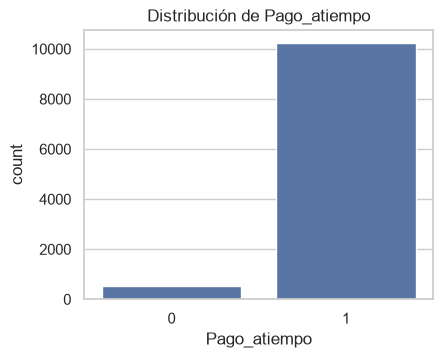

In [10]:
vc = df_limpio[TARGET].value_counts()
print(pd.DataFrame({"conteo": vc, "%": vc / vc.sum() * 100}))
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(x=TARGET, data=df_limpio, ax=ax)
ax.set_title("Distribución de Pago_atiempo")
plt.show()

**Fuerte desbalance:** ~95% pagan a tiempo y solo ~5% no. Consecuencias para el modelo: la *accuracy* es engañosa (un modelo que siempre diga "1" acierta 95%); habrá que usar métricas como recall/precision de la clase 0, PR-AUC o F1, **validación estratificada** y probar técnicas de balanceo (`class_weight`, SMOTE o ajuste de umbral).

### 3.2 Variables numéricas: estadística descriptiva

In [11]:
num_cols = df_limpio.select_dtypes(include="number").columns.drop(TARGET).tolist()

desc = df_limpio[num_cols].describe().T
desc["moda"] = [df_limpio[c].mode().iloc[0] for c in num_cols]
desc["rango"] = desc["max"] - desc["min"]
desc["IQR"] = desc["75%"] - desc["25%"]
desc["varianza"] = df_limpio[num_cols].var()
desc["skewness"] = df_limpio[num_cols].skew()
desc["kurtosis"] = df_limpio[num_cols].kurt()
desc

,count,mean,std,min,25%,50%,75%,max,moda,rango,IQR,varianza,skewness,kurtosis
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80","1,200,000.00","41,084,152.80","1,860,009.00","3,646,735,466,988.66",3.72,35.32
plazo_meses,"10,763.00",10.58,6.63,2.00,6.00,10.00,12.00,90.00,6.00,88.00,6.00,43.98,2.46,7.78
edad_cliente,"10,763.00",43.95,15.06,19.00,33.00,42.00,53.00,123.00,40.00,104.00,20.00,226.83,1.93,7.87
salario_cliente,"10,763.00","17,216,431.46","355,476,717.60",0.00,"2,000,000.00","3,000,000.00","4,875,808.00","22,000,000,000.00","3,000,000.00","22,000,000,000.00","2,875,808.00","126,363,696,758,146,032.00",43.78,"2,211.23"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00","2,000,000.00","6,787,675,263.00","1,500,000.00","14,022,897,787,155,472.00",38.46,"1,719.28"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00","205,990.00","3,792,808.00","166,792.00","44,307,595,469.58",3.79,26.65
puntaje,"10,763.00",91.17,16.47,-38.01,95.23,95.23,95.23,95.23,95.23,133.24,0.00,271.11,-4.87,24.08
puntaje_datacredito,"10,611.00",791.53,51.43,7.00,758.00,792.00,826.00,999.00,783.00,992.00,68.00,"2,645.35",-0.99,9.98
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00,4.00,62.00,5.00,15.82,1.80,8.62
huella_consulta,"10,763.00",4.23,3.06,0.00,2.00,4.00,6.00,29.00,2.00,29.00,4.00,9.39,1.49,4.00


In [12]:
def tipo_distribucion(s):
    s = s.dropna()
    sk = s.skew()
    if abs(sk) < 0.5:
        return "aprox. simétrica / gaussiana"
    if sk >= 0.5:
        return "sesgo positivo" + (" fuerte (tipo log-normal)" if sk > 2 and (s >= 0).all() else "")
    return "sesgo negativo"

pd.DataFrame({"skew": df_limpio[num_cols].skew(),
              "distribución": [tipo_distribucion(df_limpio[c]) for c in num_cols]}).sort_values("skew")

,skew,distribución
puntaje,-4.87,sesgo negativo
puntaje_datacredito,-0.99,sesgo negativo
huella_consulta,1.49,sesgo positivo
cant_creditosvigentes,1.80,sesgo positivo
edad_cliente,1.93,sesgo positivo
plazo_meses,2.46,sesgo positivo fuerte (tipo log-normal)
creditos_sectorFinanciero,2.70,sesgo positivo fuerte (tipo log-normal)
creditos_sectorReal,3.16,sesgo positivo fuerte (tipo log-normal)
capital_prestado,3.72,sesgo positivo fuerte (tipo log-normal)
cuota_pactada,3.79,sesgo positivo fuerte (tipo log-normal)


**Interpretación general:**
- Casi todas las variables monetarias (`capital_prestado`, `salario_cliente`, `total_otros_prestamos`, `cuota_pactada`, saldos, `promedio_ingresos_datacredito`) tienen **sesgo positivo fuerte y colas largas** (comportamiento log-normal): la media es mucho mayor que la mediana. Se recomienda transformación **logarítmica** o escalado robusto.
- Las variables de conteo (`cant_creditosvigentes`, `huella_consulta`, créditos por sector, `saldo_mora`) están muy concentradas en valores bajos y con muchos ceros.
- `puntaje_datacredito` es la menos sesgada de las variables continuas (skew ≈ -1, cola hacia valores bajos); `edad_cliente` tiene sesgo positivo moderado (≈ 1.9) por los casos de edad improbable.
- `puntaje` tiene un pico enorme en un único valor (95.23) con cola hacia la izquierda (skew ≈ -4.9): distribución degenerada, no gaussiana.

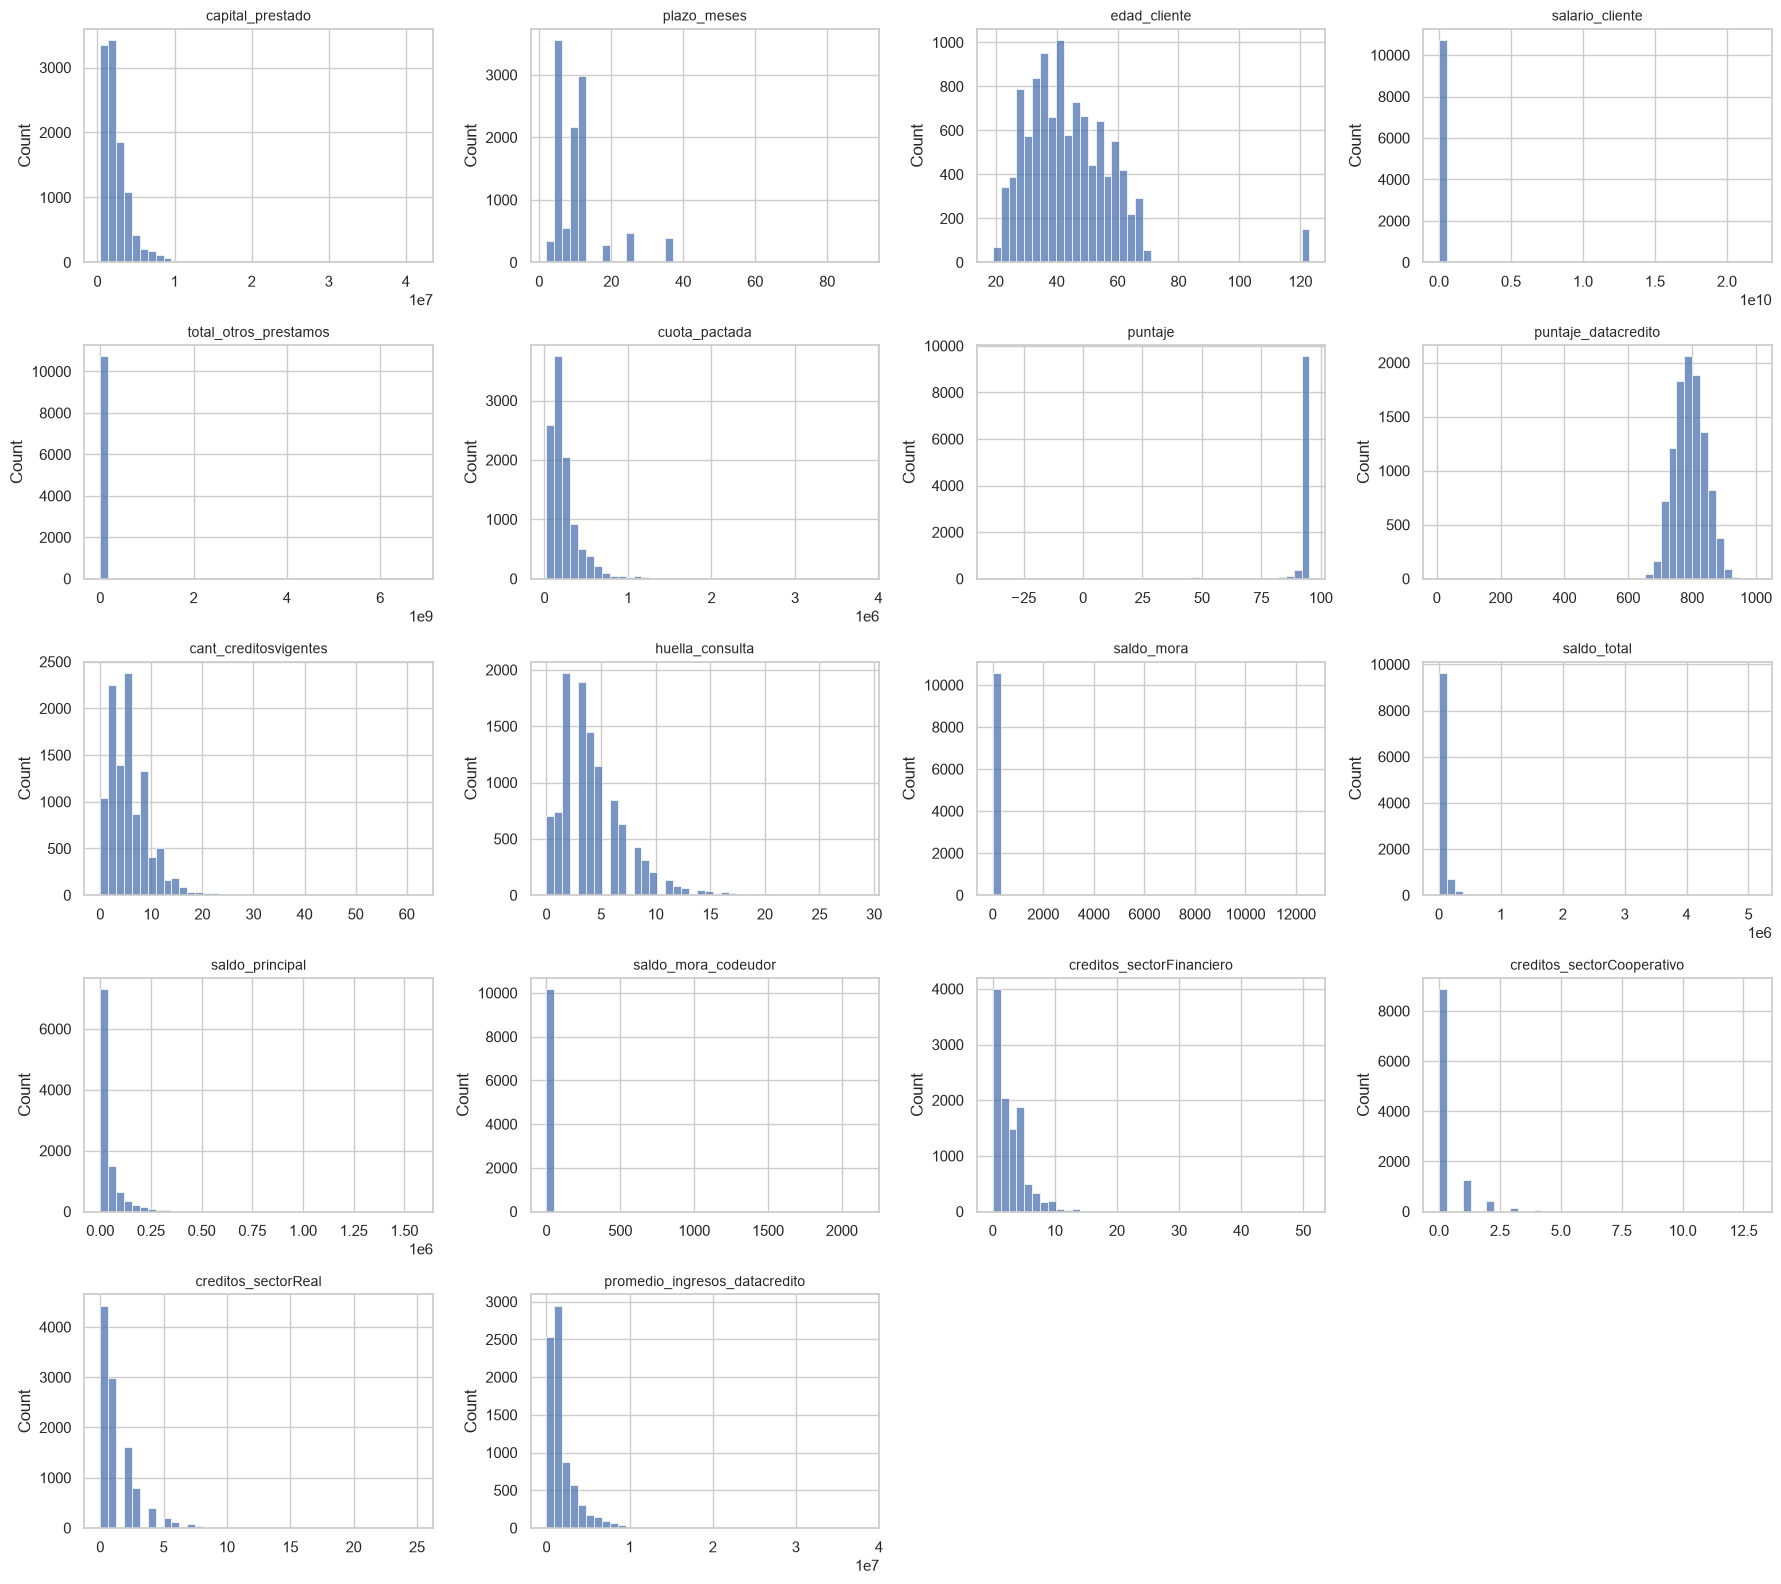

In [13]:
# Histogramas
fig, axes = plt.subplots(5, 4, figsize=(18, 16))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df_limpio[col].dropna(), bins=40, kde=False, ax=ax)
    ax.set_title(col, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

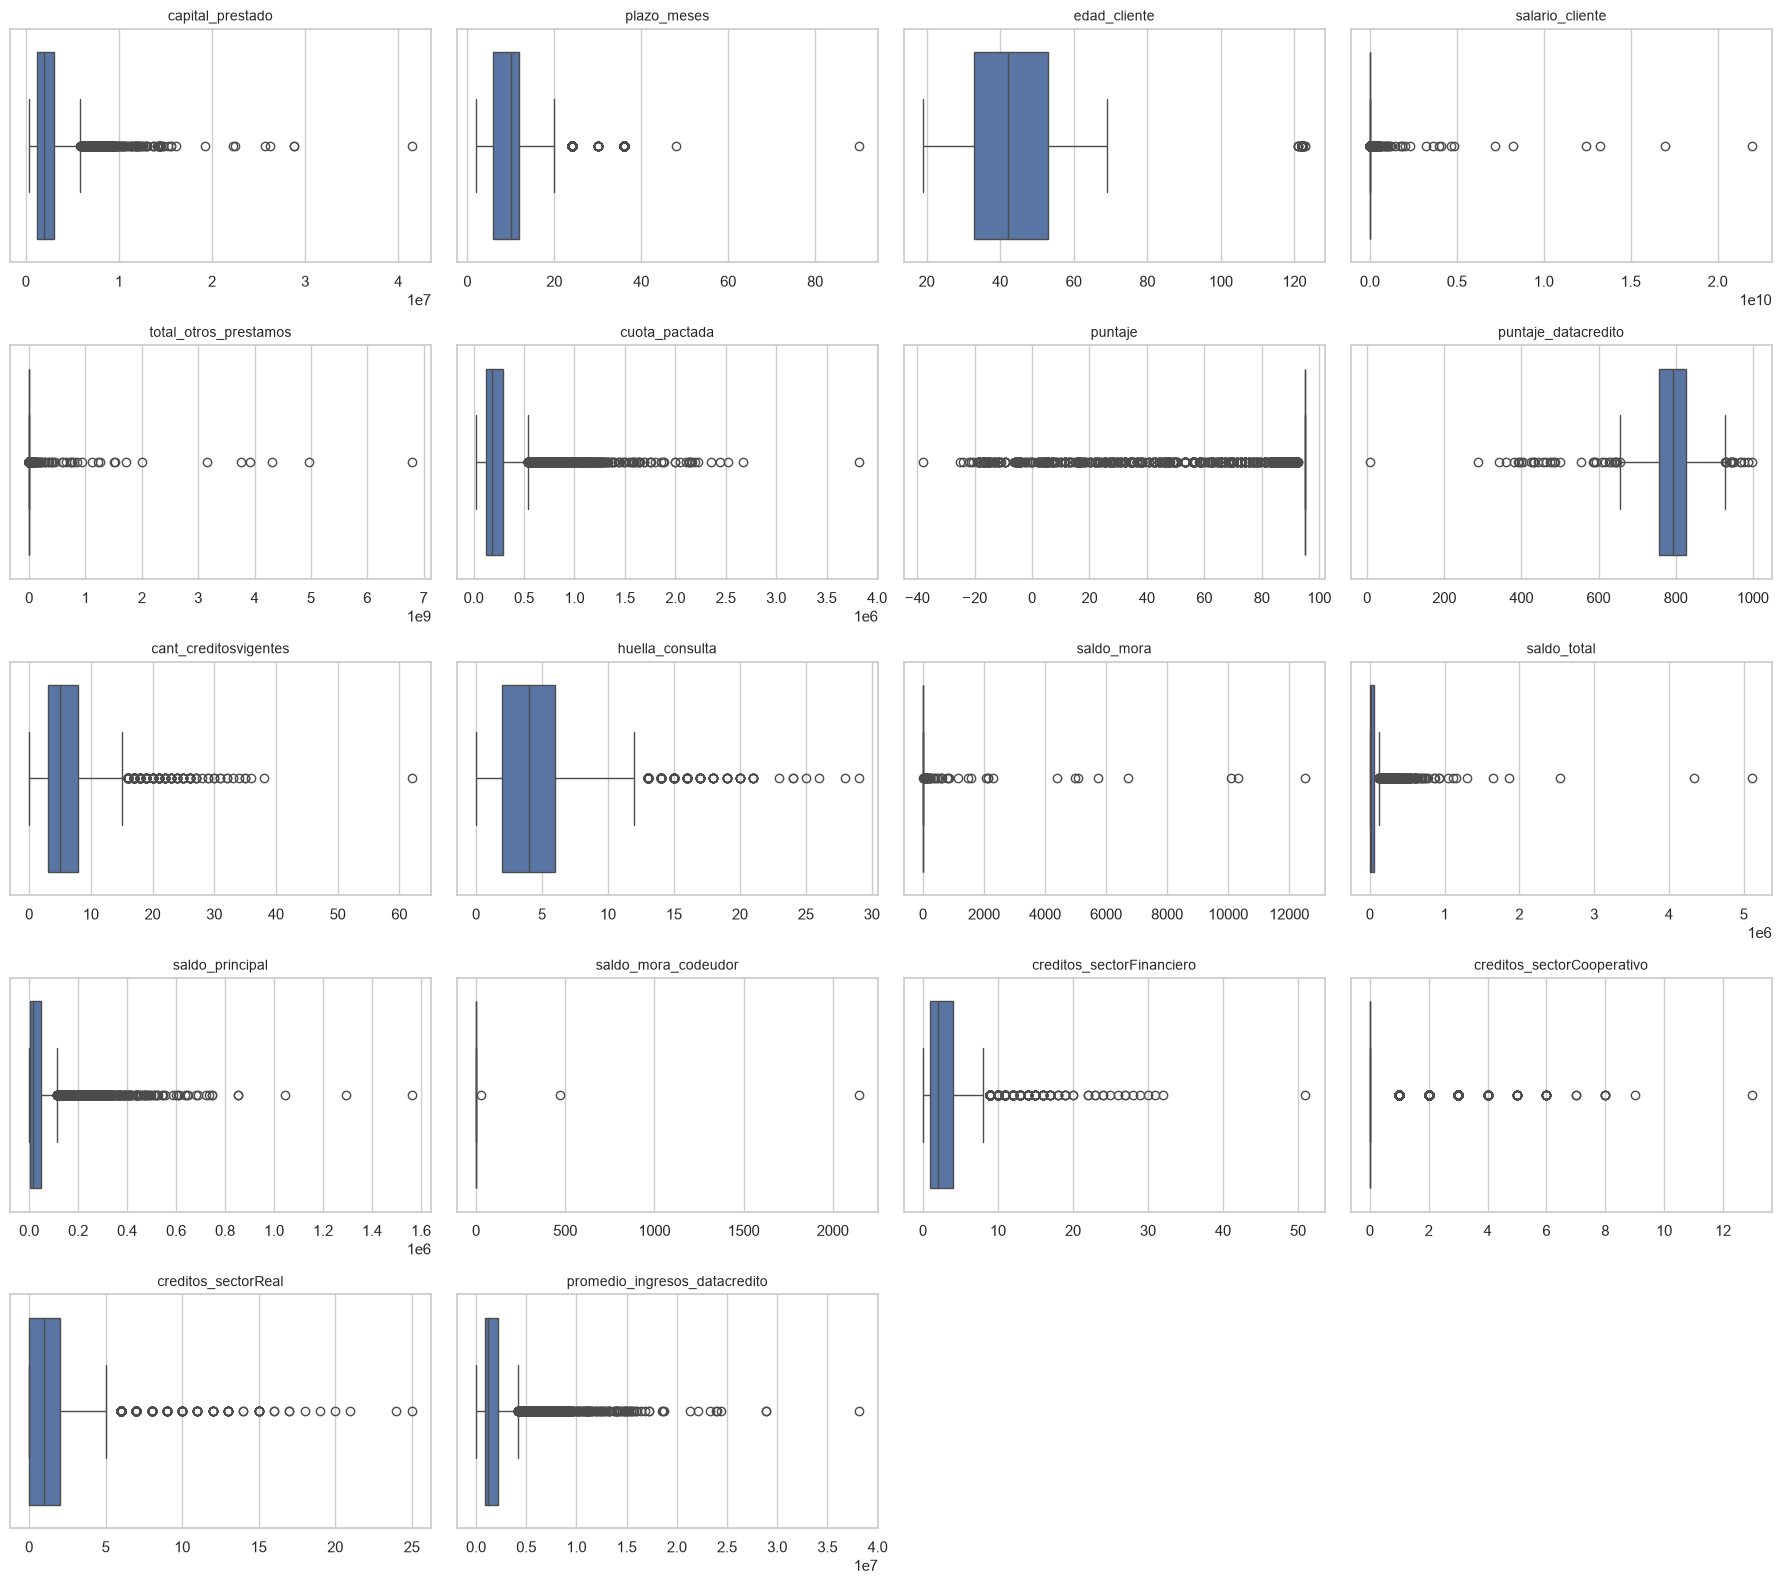

In [14]:
# Boxplots
fig, axes = plt.subplots(5, 4, figsize=(18, 16))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df_limpio[col], ax=ax)
    ax.set_title(col, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [15]:
# Outliers por regla IQR
def pct_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean() * 100

pd.Series({c: pct_outliers(df_limpio[c]) for c in num_cols}, name="% outliers (IQR)").sort_values(ascending=False)

creditos_sectorCooperativo      17.61
puntaje                         12.60
promedio_ingresos_datacredito   10.01
saldo_principal                  9.18
saldo_total                      9.14
plazo_meses                      8.07
cuota_pactada                    7.11
salario_cliente                  6.67
total_otros_prestamos            5.47
capital_prestado                 5.11
creditos_sectorFinanciero        3.38
creditos_sectorReal              3.25
cant_creditosvigentes            2.25
huella_consulta                  2.01
edad_cliente                     1.39
saldo_mora                       0.52
puntaje_datacredito              0.47
saldo_mora_codeudor              0.03
Name: % outliers (IQR), dtype: float64

**Outliers:** varias variables monetarias superan el 5–10% de valores atípicos por regla IQR, pero la mayoría es **cola natural** de una distribución log-normal (no error). Lo que sí parece error son los casos extremos (salario de 22.000 millones, edad 123). Se recomienda no eliminar filas (hay pocas clases 0) y usar topes por percentil o transformaciones.

### 3.3 Variables categóricas

--- tipo_credito ---
tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64

--- tipo_laboral ---
tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64

--- tendencia_ingresos ---
tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64



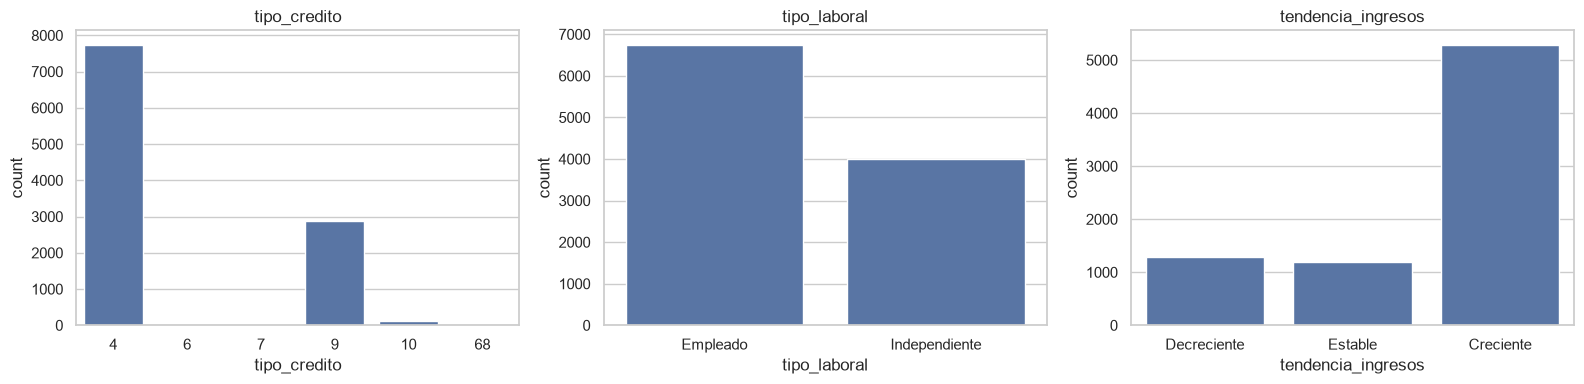

In [16]:
cat_cols = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]
for col in cat_cols:
    print(f"--- {col} ---")
    print(df_limpio[col].value_counts(dropna=False))
    print()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, cat_cols):
    sns.countplot(x=col, data=df_limpio, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

**Interpretación:**
- `tipo_credito`: dominan los códigos **4 (72%)** y **9 (27%)**; los códigos 6, 7, 10 y 68 suman menos de 2%. Para el modelo conviene **agrupar los códigos raros en "Otros"** (el 68 tiene un único registro).
- `tipo_laboral`: 63% empleados, 37% independientes.
- `tendencia_ingresos`: ~27% nulos (mismos clientes sin `promedio_ingresos_datacredito`) y más "Creciente" que "Decreciente".

### 3.4 Comportamiento en el tiempo

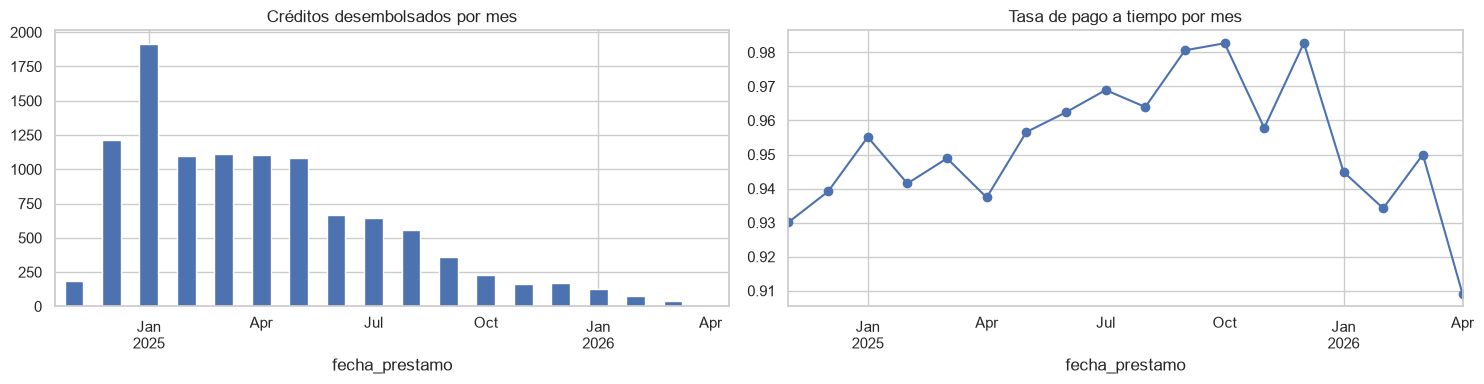

,creditos,tasa_pago
fecha_prestamo,,
2024-11,186,0.93
2024-12,1216,0.94
2025-01,1917,0.96
2025-02,1094,0.94
2025-03,1115,0.95
2025-04,1102,0.94
2025-05,1083,0.96
2025-06,665,0.96
2025-07,644,0.97


In [17]:
por_mes = df_limpio.groupby(df_limpio["fecha_prestamo"].dt.to_period("M")).agg(
    creditos=(TARGET, "size"), tasa_pago=(TARGET, "mean"))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
por_mes["creditos"].plot(kind="bar", ax=ax[0], title="Créditos desembolsados por mes")
por_mes["tasa_pago"].plot(marker="o", ax=ax[1], title="Tasa de pago a tiempo por mes")
plt.tight_layout(); plt.show()
por_mes

**Observación importante:** el volumen de desembolsos cae con el tiempo (de ~1.900 en ene-2025 a menos de 130 al mes en 2026). La tasa de pago sube de ~94% a ~98% durante 2025 y en 2026 se vuelve inestable porque hay muy pocos créditos por mes. Una posible explicación es que los créditos recientes han tenido menos tiempo para caer en mora, por lo que su etiqueta podría estar **incompleta**; hay que confirmarlo con el negocio. Esto sugiere validar con un corte temporal y no sobreinterpretar los meses recientes.

## 4. Análisis bivariable (frente a `Pago_atiempo`)
### 4.1 Numéricas vs objetivo

In [18]:
tabla = df_limpio.groupby(TARGET)[num_cols].median().T
tabla.columns = ["mediana (no pagó = 0)", "mediana (pagó = 1)"]
tabla["diferencia %"] = (tabla.iloc[:, 1] / tabla.iloc[:, 0] - 1) * 100
tabla

,mediana (no pagó = 0),mediana (pagó = 1),diferencia %
capital_prestado,"2,268,000.00","1,908,446.40",-15.85
plazo_meses,10.00,10.00,0.00
edad_cliente,38.00,42.00,10.53
salario_cliente,"3,000,000.00","3,000,000.00",0.00
total_otros_prestamos,"900,000.00","1,000,000.00",11.11
cuota_pactada,"199,002.00","182,576.00",-8.25
puntaje,25.42,95.23,274.63
puntaje_datacredito,769.00,792.00,2.99
cant_creditosvigentes,5.00,5.00,0.00
huella_consulta,5.00,4.00,-20.00


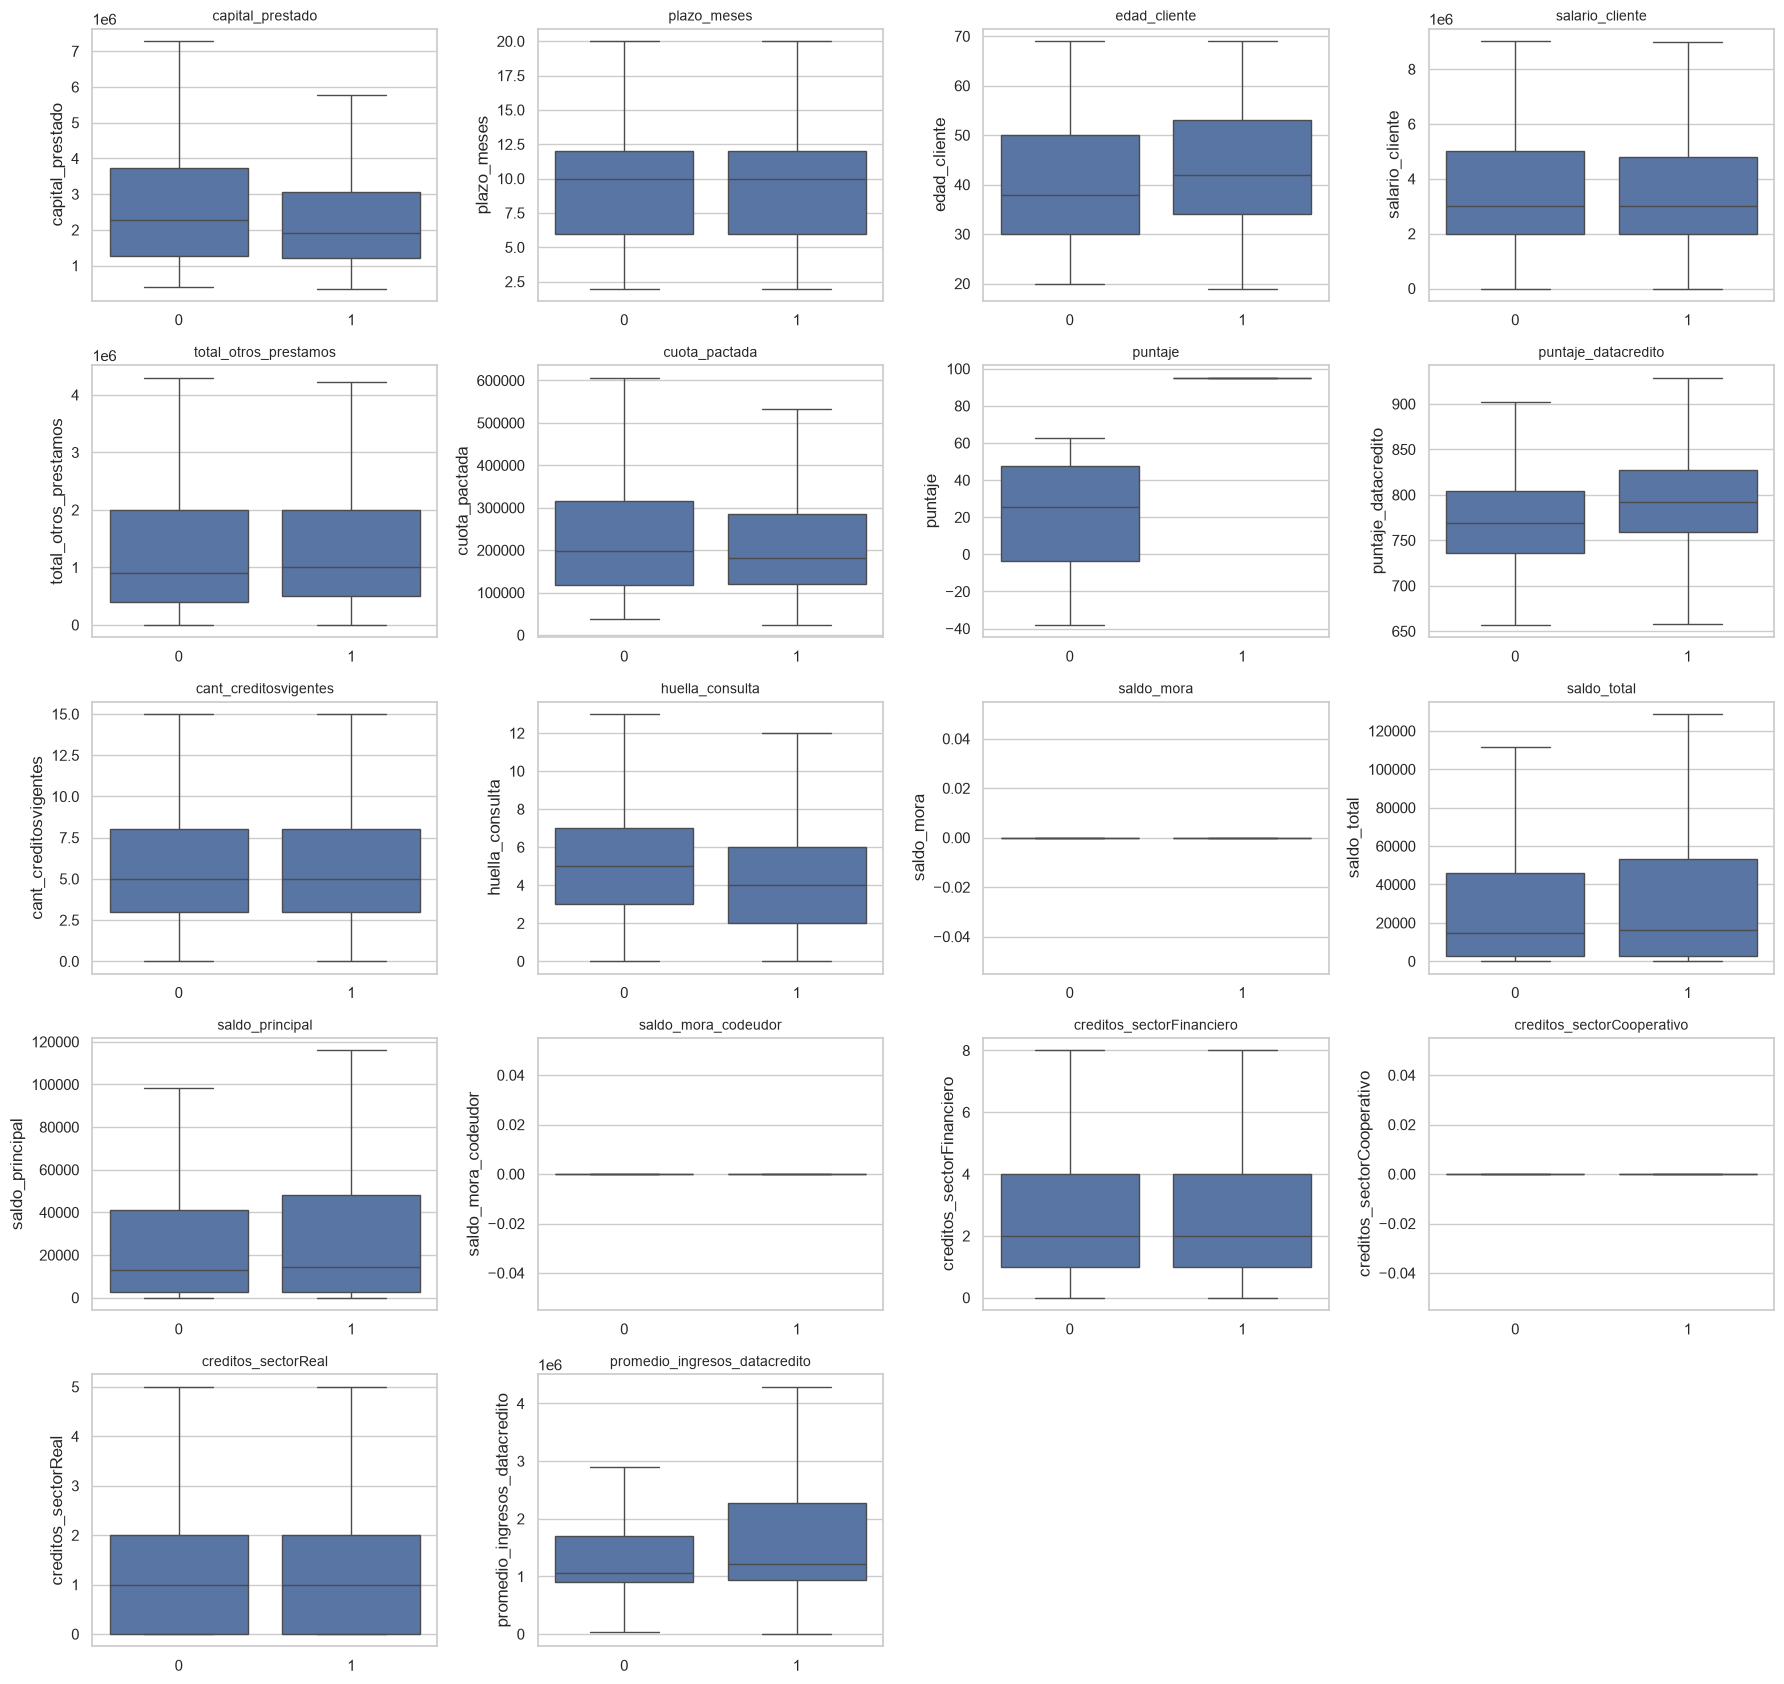

In [19]:
fig, axes = plt.subplots(5, 4, figsize=(18, 17))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=TARGET, y=col, data=df_limpio, ax=ax, showfliers=False)
    ax.set_title(col, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [20]:
# Prueba estadística (Mann-Whitney, no asume normalidad) + tamaño del efecto
res = []
for col in num_cols:
    a = df_limpio.loc[df_limpio[TARGET] == 0, col].dropna()
    b = df_limpio.loc[df_limpio[TARGET] == 1, col].dropna()
    u, p = stats.mannwhitneyu(a, b)
    auc = u / (len(a) * len(b))          # prob. de que un "no pagó" tenga valor mayor
    res.append((col, p, auc))
pd.DataFrame(res, columns=["variable", "p_valor", "AUC_univariado(0>1)"]).sort_values("p_valor")

,variable,p_valor,AUC_univariado(0>1)
6,puntaje,0.00,0.00
10,saldo_mora,0.00,0.52
7,puntaje_datacredito,0.00,0.38
9,huella_consulta,0.00,0.60
2,edad_cliente,0.00,0.43
17,promedio_ingresos_datacredito,0.00,0.43
0,capital_prestado,0.00,0.56
14,creditos_sectorFinanciero,0.00,0.46
4,total_otros_prestamos,0.01,0.46
15,creditos_sectorCooperativo,0.01,0.48


**Hallazgos bivariados (numéricas):**
- Los clientes que **no pagan** tienen en mediana mayor `capital_prestado`, mayor `cuota_pactada`, **más consultas (`huella_consulta`)** y menor `puntaje_datacredito` e ingresos promedio.
- Las diferencias son pequeñas y varias variables **no son estadísticamente significativas** (p > 0.05: `salario_cliente`, `saldo_mora_codeudor`, `saldo_principal`, `cuota_pactada`, `saldo_total`, `cant_creditosvigentes`, `plazo_meses`). El efecto individual es **débil**; es normal en riesgo de crédito, donde la señal viene de combinaciones de variables.
- `puntaje` separa casi perfectamente las dos clases (mediana ≈ 25 vs ≈ 95): ver alerta en 4.4.

### 4.2 Categóricas vs objetivo

--- tipo_credito ---
              registros  tasa_pago  tasa_no_pago
tipo_credito                                    
4                  7747       0.95          0.05
6                    21       0.57          0.43
7                     2       1.00          0.00
9                  2876       0.95          0.05
10                  116       0.97          0.03
68                    1       1.00          0.00 

--- tipo_laboral ---
               registros  tasa_pago  tasa_no_pago
tipo_laboral                                     
Empleado            6754       0.96          0.04
Independiente       4009       0.94          0.06 

--- tendencia_ingresos ---
                    registros  tasa_pago  tasa_no_pago
tendencia_ingresos                                    
Decreciente              1291       0.94          0.06
Estable                  1188       0.95          0.05
Creciente                5294       0.96          0.04
NaN                      2990       0.94          0.06 



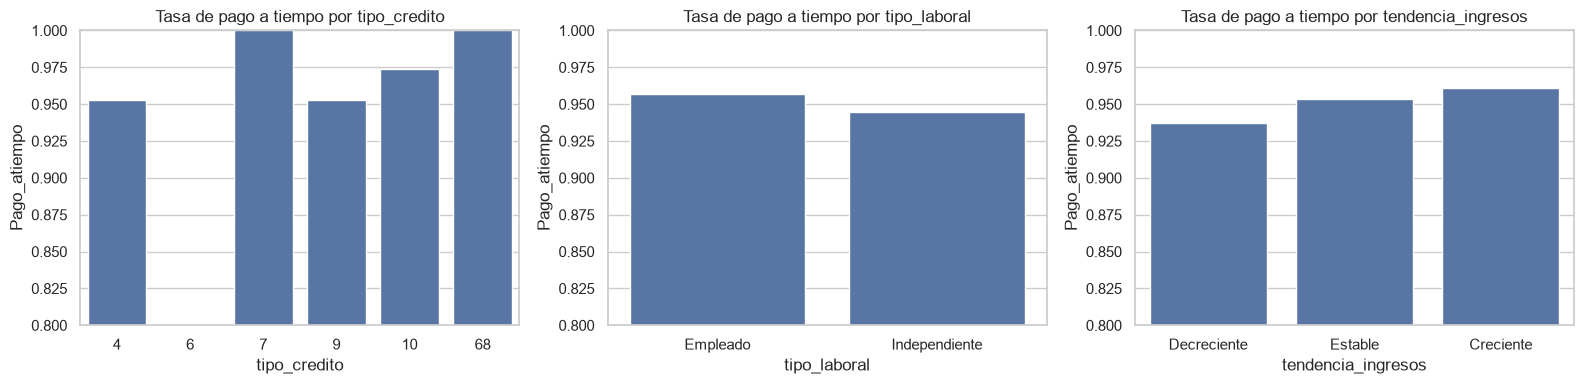

In [21]:
for col in cat_cols:
    t = (df_limpio.groupby(col, dropna=False, observed=True)[TARGET]
         .agg(registros="size", tasa_pago="mean"))
    t["tasa_no_pago"] = 1 - t["tasa_pago"]
    print(f"--- {col} ---"); print(t, "\n")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, cat_cols):
    sns.barplot(x=col, y=TARGET, data=df_limpio, ax=ax, errorbar=None)
    ax.set_title(f"Tasa de pago a tiempo por {col}"); ax.set_ylim(0.8, 1.0)
plt.tight_layout(); plt.show()

In [22]:
# Chi-cuadrado de independencia
for col in cat_cols:
    ct = pd.crosstab(df_limpio[col].astype(object).fillna("SIN_DATO"), df_limpio[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    print(f"{col:20s} chi2={chi2:8.2f}  p={p:.4f}")

tipo_credito         chi2=   68.86  p=0.0000
tipo_laboral         chi2=    8.00  p=0.0047
tendencia_ingresos   chi2=   19.92  p=0.0002


**Hallazgos (categóricas):**
- `tendencia_ingresos`: "Decreciente" tiene la mayor tasa de no pago (~6.3%) frente a "Creciente" (~3.9%). Es una relación **ordinal coherente con el negocio**.
- `tipo_laboral`: independientes pagan algo menos que empleados (94.5% vs 95.7%), diferencia pequeña.
- `tipo_credito`: los códigos 4 y 9 son casi idénticos (~95.3%); el código 6 tiene tasa baja (57%) pero con **solo 21 registros**, no concluyente.

### 4.3 Nulos como señal

In [23]:
for col in ["promedio_ingresos_datacredito", "saldo_principal", "saldo_mora_codeudor"]:
    print(df_limpio.groupby(df_limpio[col].isna())[TARGET].agg(["size", "mean"]).rename(
        index={False: f"{col}: con dato", True: f"{col}: sin dato"}), "\n")

print("Mora > 0 vs mora = 0")
print(df_limpio.groupby(df_limpio["saldo_mora"] > 0)[TARGET].agg(["size", "mean"]))

                                         size  mean
promedio_ingresos_datacredito                      
promedio_ingresos_datacredito: con dato  7833  0.96
promedio_ingresos_datacredito: sin dato  2930  0.94 

                            size  mean
saldo_principal                       
saldo_principal: con dato  10358  0.95
saldo_principal: sin dato    405  0.93 

                                size  mean
saldo_mora_codeudor                       
saldo_mora_codeudor: con dato  10173  0.95
saldo_mora_codeudor: sin dato    590  0.93 

Mora > 0 vs mora = 0
             size  mean
saldo_mora             
False       10708  0.95
True           55  0.64


- Los clientes **sin ingresos reportados** pagan un poco peor (94.3% vs 95.6%): el propio hecho de faltar el dato es informativo → crear indicadores `*_sin_dato`.
- **`saldo_mora > 0` es muy predictivo**: solo 63.6% paga a tiempo (vs 95.4%), pero afecta a solo ~55 clientes.

### 4.4 Alerta: posible fuga de datos (`puntaje`)

Correlación puntaje vs objetivo: 0.923

                 count  mean   std    min   25%   50%   75%   max
Pago_atiempo                                                     
0               511.00 23.09 26.07 -38.01 -3.59 25.42 47.61 62.67
1            10,252.00 94.56  2.87  63.81 95.23 95.23 95.23 95.23

Pago_atiempo según si puntaje es el valor máximo (95.2278):
         size  mean
puntaje            
False    1356  0.62
True     9407  1.00


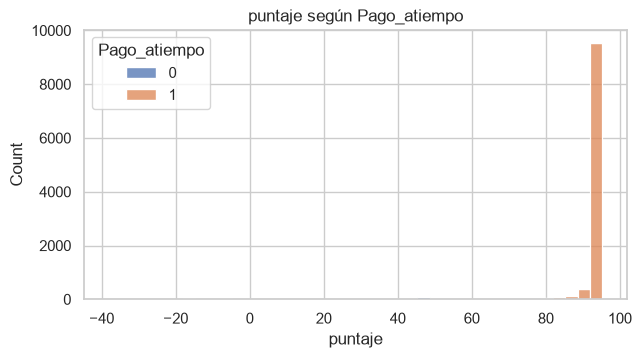

In [24]:
print("Correlación puntaje vs objetivo:", round(df_limpio["puntaje"].corr(df_limpio[TARGET]), 3))
print()
print(df_limpio.groupby(TARGET)["puntaje"].describe())
print("\nPago_atiempo según si puntaje es el valor máximo (95.2278):")
maxp = df_limpio["puntaje"].max()
print(df_limpio.groupby(df_limpio["puntaje"] == maxp)[TARGET].agg(["size", "mean"]))

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(data=df_limpio, x="puntaje", hue=TARGET, bins=40, ax=ax, multiple="stack")
ax.set_title("puntaje según Pago_atiempo")
plt.show()

**⚠️ Hallazgo crítico.** `puntaje` tiene correlación ≈ **0.92** con el objetivo; tomar el valor máximo implica casi seguro que el cliente pagó a tiempo, y valores menores concentran a quienes no pagaron. Además, los 511 clientes que no pagaron tienen todos `puntaje` ≤ 62.7, mientras que el 100% de quienes tienen el valor máximo pagó. Una relación tan fuerte entre una variable y la etiqueta es **inusual** en datos de riesgo y sugiere que `puntaje` se **calcula después** de observar el comportamiento de pago (por ejemplo, un score de comportamiento actualizado con el atraso).

Si fuera así, usarla en el modelo sería **fuga de datos (data leakage)**: el modelo daría métricas excelentes en validación pero **no serviría en producción**, porque al momento de aprobar un crédito ese valor aún no existe.

**Acción:** confirmar con el área de negocio cuándo se genera `puntaje`. Mientras tanto, se propone entrenar **sin** `puntaje` como escenario principal y, opcionalmente, con ella solo como referencia.

## 5. Análisis multivariable
### 5.1 Matriz de correlación

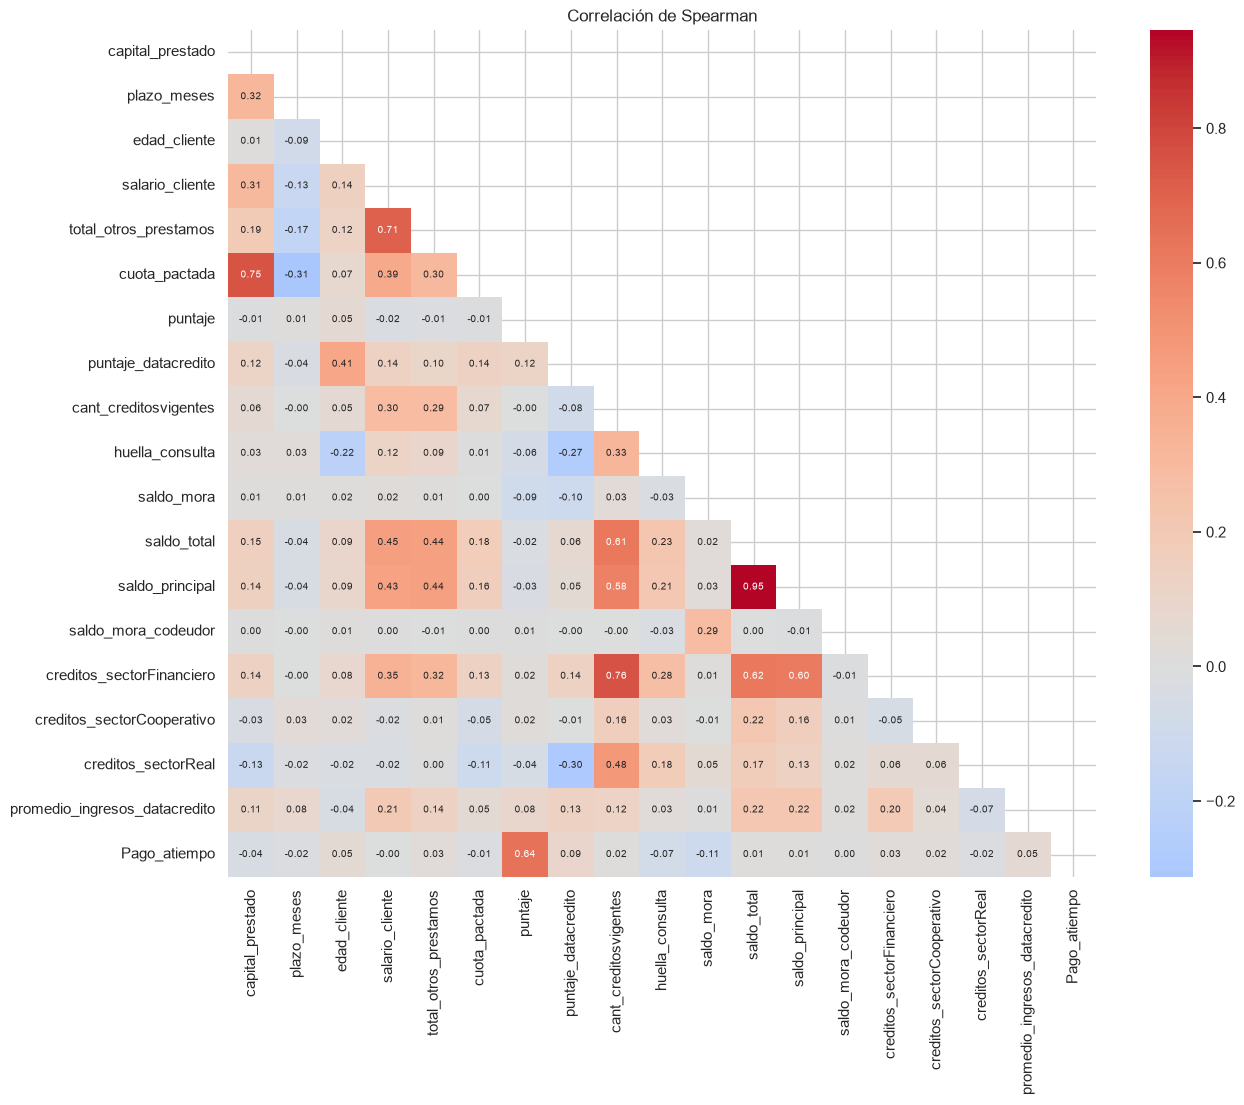

In [25]:
corr = df_limpio[num_cols + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlación de Spearman")
plt.show()

In [26]:
# Pares muy correlacionados (posible redundancia)
pares = corr.where(~mask).stack().reset_index()
pares.columns = ["var_1", "var_2", "corr"]
pares[pares["corr"].abs() > 0.7].sort_values("corr", key=abs, ascending=False)

,var_1,var_2,corr
239,saldo_principal,saldo_total,0.95
274,creditos_sectorFinanciero,cant_creditosvigentes,0.76
95,cuota_pactada,capital_prestado,0.75
79,total_otros_prestamos,salario_cliente,0.71


**Interpretación:**
- `saldo_total` y `saldo_principal` están casi perfectamente correlacionados (0.95, redundantes); `capital_prestado` con `cuota_pactada` (0.75, la cuota se deriva del monto y plazo) y `salario_cliente` con `total_otros_prestamos` (0.71) también son altas. Para modelos lineales conviene dejar una sola de cada par o usar regularización.
- `creditos_sectorFinanciero` se relaciona con `cant_creditosvigentes` (el total incluye los sectores).
- Con el objetivo, salvo `puntaje`, **ninguna correlación supera ~0.1 en valor absoluto**: señal débil y distribuida.

### 5.2 Relaciones entre variables y gráficos con `hue`

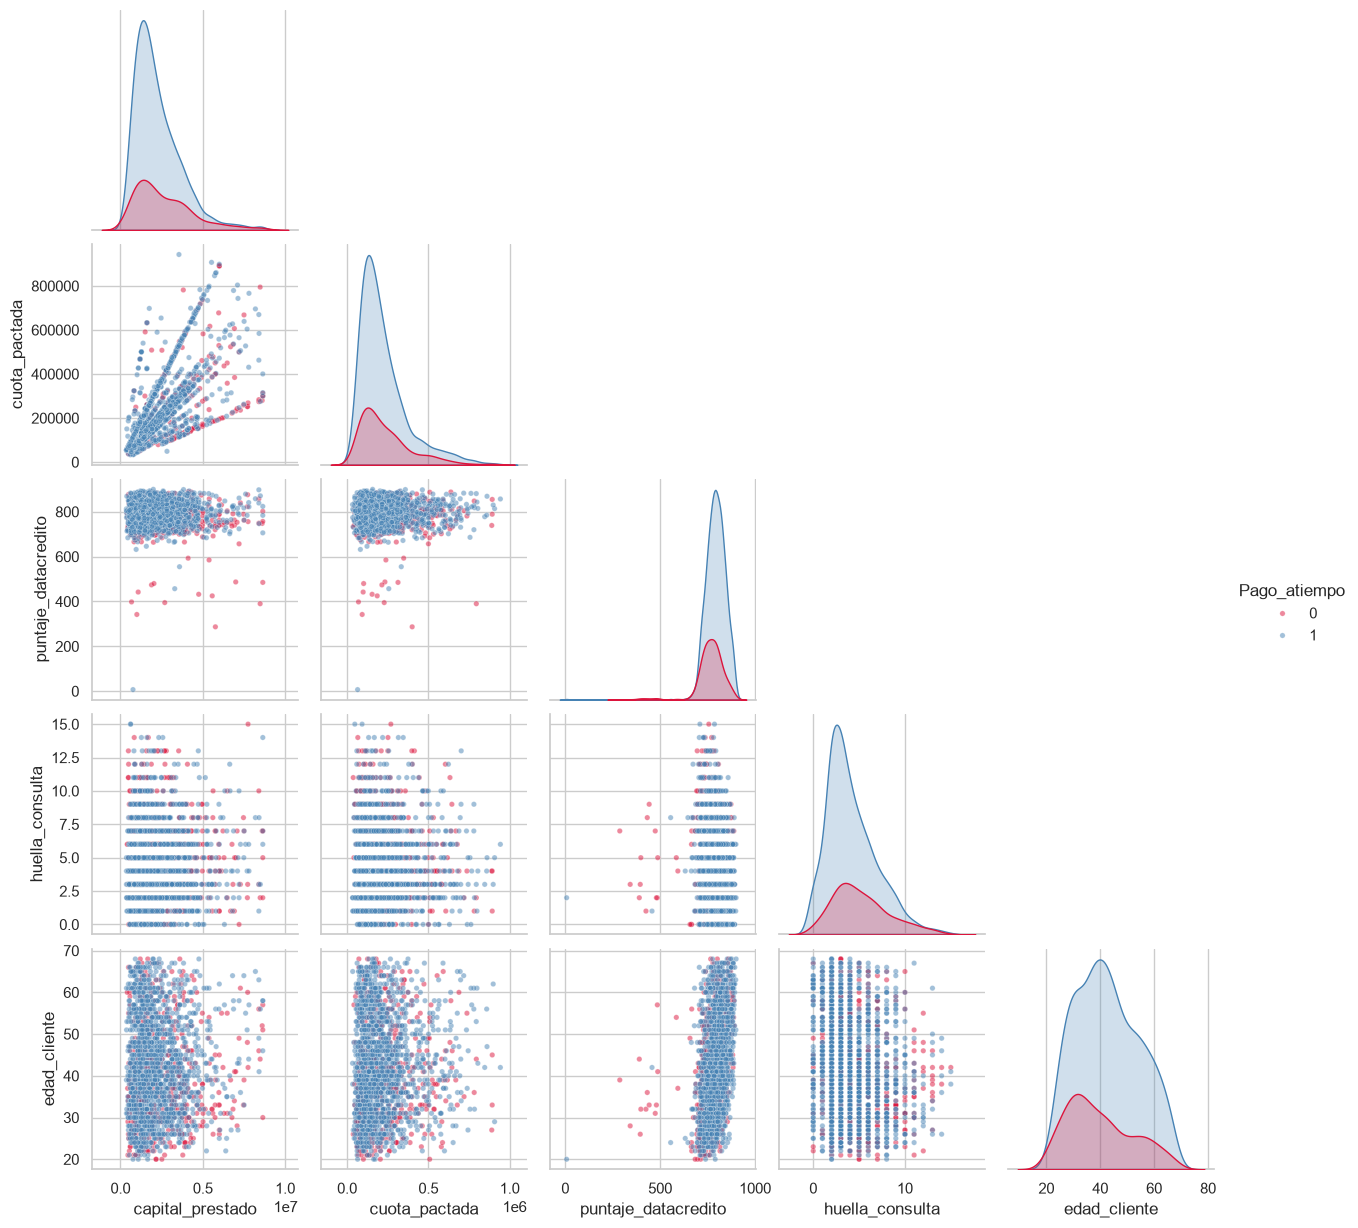

In [27]:
# Para visualizar se limita a percentil 99 y se toma muestra
cols_pair = ["capital_prestado", "cuota_pactada", "puntaje_datacredito", "huella_consulta", "edad_cliente"]
dfp = df_limpio[cols_pair + [TARGET]].dropna()
for c_ in cols_pair:
    dfp = dfp[dfp[c_] <= dfp[c_].quantile(0.99)]
# se muestrean todos los casos de clase 0 y una muestra de la clase 1 para que se vean
muestra = pd.concat([dfp[dfp[TARGET] == 0], dfp[dfp[TARGET] == 1].sample(1500, random_state=42)])
sns.pairplot(muestra, hue=TARGET, corner=True, plot_kws={"alpha": 0.5, "s": 15}, palette={0: "crimson", 1: "steelblue"})
plt.show()

In [28]:
# Tasa de pago por combinación de variables (tablas cruzadas)
df_limpio["rango_puntaje_dc"] = pd.cut(df_limpio["puntaje_datacredito"], [0, 650, 750, 800, 850, 1000])
print(pd.crosstab(df_limpio["rango_puntaje_dc"], df_limpio["tendencia_ingresos"],
                  values=df_limpio[TARGET], aggfunc="mean").round(3))
print()
print(pd.crosstab(df_limpio["tipo_laboral"], pd.cut(df_limpio["huella_consulta"], [-1, 2, 5, 8, 40]),
                  values=df_limpio[TARGET], aggfunc="mean").round(3))

tendencia_ingresos  Decreciente  Estable  Creciente
rango_puntaje_dc                                   
(0, 650]                   0.50     0.20       0.56
(650, 750]                 0.90     0.94       0.93
(750, 800]                 0.93     0.94       0.96
(800, 850]                 0.96     0.97       0.98
(850, 1000]                0.99     0.98       0.98

huella_consulta  (-1, 2]  (2, 5]  (5, 8]  (8, 40]
tipo_laboral                                     
Empleado            0.97    0.96    0.94     0.91
Independiente       0.97    0.94    0.94     0.92


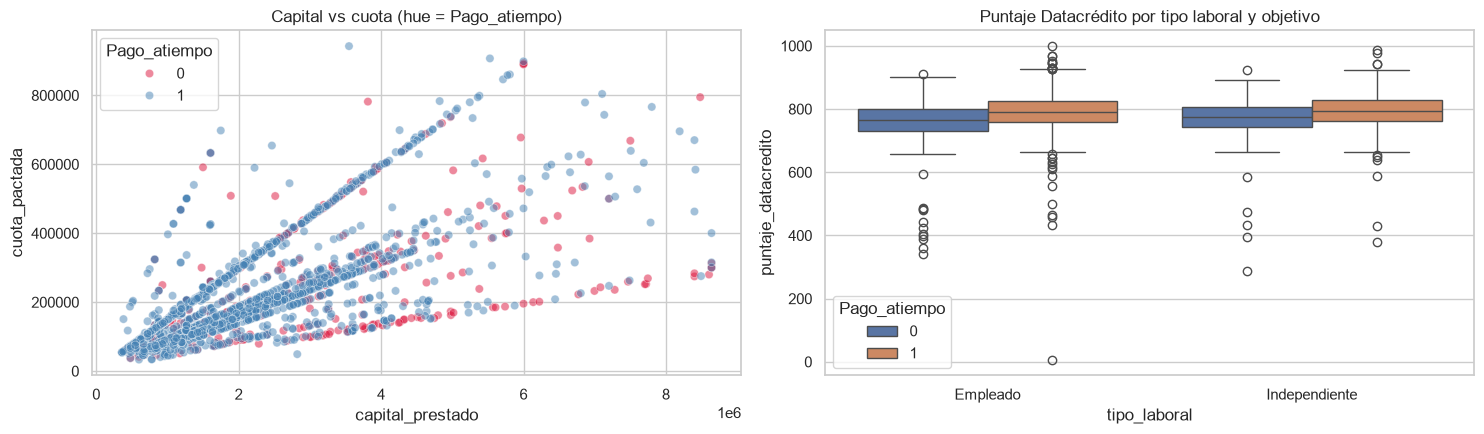

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.scatterplot(data=muestra, x="capital_prestado", y="cuota_pactada", hue=TARGET,
                palette={0: "crimson", 1: "steelblue"}, alpha=.5, ax=axes[0])
axes[0].set_title("Capital vs cuota (hue = Pago_atiempo)")
sns.boxplot(data=df_limpio, x="tipo_laboral", y="puntaje_datacredito", hue=TARGET, ax=axes[1])
axes[1].set_title("Puntaje Datacrédito por tipo laboral y objetivo")
plt.tight_layout(); plt.show()
df_limpio.drop(columns="rango_puntaje_dc", inplace=True)

**Interpretación:** el riesgo no se explica por una sola variable. Los clientes con **puntaje Datacrédito bajo, ingresos decrecientes y muchas consultas** concentran la mayor tasa de no pago. Capital y cuota crecen juntos (relación casi lineal, dependiente del plazo).

## 6. Reglas de validación de datos (para etapas posteriores)
Con base en el análisis se proponen estas reglas para validar los datos que lleguen al pipeline (`ft_engineering.py` / monitoreo):

In [30]:
REGLAS_VALIDACION = {
    "tipo_credito":        {"tipo": "categorica", "valores": [4, 6, 7, 9, 10, 68]},   # códigos nuevos -> alerta
    "tipo_laboral":        {"tipo": "categorica", "valores": ["Empleado", "Independiente"]},
    "tendencia_ingresos":  {"tipo": "categorica", "valores": ["Decreciente", "Estable", "Creciente"], "nulos": True},
    "capital_prestado":    {"tipo": "numerica", "min": 1, "max": 100_000_000},
    "plazo_meses":         {"tipo": "numerica", "min": 1, "max": 120, "entero": True},
    "edad_cliente":        {"tipo": "numerica", "min": 18, "max": 90, "entero": True},
    "salario_cliente":     {"tipo": "numerica", "min": 0, "max": 100_000_000},
    "total_otros_prestamos": {"tipo": "numerica", "min": 0, "max": 1_000_000_000},
    "cuota_pactada":       {"tipo": "numerica", "min": 1},
    "puntaje_datacredito": {"tipo": "numerica", "min": 1, "max": 999, "nulos": True},
    "cant_creditosvigentes": {"tipo": "numerica", "min": 0, "entero": True},
    "huella_consulta":     {"tipo": "numerica", "min": 0, "entero": True},
    "saldo_mora":          {"tipo": "numerica", "min": 0, "nulos": True},
    "saldo_total":         {"tipo": "numerica", "min": 0, "nulos": True},
    "saldo_principal":     {"tipo": "numerica", "min": 0, "nulos": True},
    "saldo_mora_codeudor": {"tipo": "numerica", "min": 0, "nulos": True},
    "promedio_ingresos_datacredito": {"tipo": "numerica", "min": 0, "nulos": True},
    TARGET:                {"tipo": "binaria", "valores": [0, 1]},
}
REGLAS_CRUZADAS = [
    "saldo_principal <= saldo_total",
    "cuota_pactada <= capital_prestado",
    "creditos_sectorFinanciero + creditos_sectorCooperativo + creditos_sectorReal <= cant_creditosvigentes (revisar)",
]

def validar(df_, reglas=REGLAS_VALIDACION):
    informe = []
    for col, r in reglas.items():
        if col not in df_.columns:
            informe.append((col, "columna ausente", len(df_))); continue
        s = df_[col]
        if not r.get("nulos") and s.isna().any():
            informe.append((col, "nulos no permitidos", int(s.isna().sum())))
        if "valores" in r:
            fuera = ~s.dropna().isin(r["valores"])
            if fuera.any(): informe.append((col, "valor fuera de catálogo", int(fuera.sum())))
        if "min" in r:
            n = int((s < r["min"]).sum())
            if n: informe.append((col, f"< {r['min']}", n))
        if "max" in r:
            n = int((s > r["max"]).sum())
            if n: informe.append((col, f"> {r['max']}", n))
    return pd.DataFrame(informe, columns=["columna", "regla incumplida", "registros"])

# Se aplica sobre los datos ORIGINALES para ver qué reglas se violan hoy
validar(df)

,columna,regla incumplida,registros
0,tendencia_ingresos,valor fuera de catálogo,58
1,edad_cliente,> 90,150
2,salario_cliente,> 100000000,74
3,total_otros_prestamos,> 1000000000,13
4,puntaje_datacredito,< 1,146


Las violaciones que aparecen arriba son las que el pipeline debe **detectar y tratar** (corregir, topar o marcar). Las reglas cruzadas se revisarán con el negocio antes de volverlas obligatorias.

## 7. Transformaciones sugeridas y variables derivadas
### 7.1 Transformaciones
| Problema detectado | Transformación propuesta |
|---|---|
| Sesgo positivo fuerte en variables monetarias | `log1p` o `RobustScaler` |
| Outliers extremos (salario, edad, deudas) | Winsorizar en percentil 1–99 |
| Nulos con significado (`promedio_ingresos`, `tendencia`) | Indicador `*_sin_dato` + imputación (mediana / categoría "SIN_DATO") |
| Nulos en saldos | Imputar con 0 o mediana, más indicador |
| `puntaje_datacredito` ≤ 0 | Tratar como nulo, imputar con mediana |
| `tipo_credito` con códigos raros | Agrupar 6, 7, 10, 68 en "Otros"; luego One-Hot |
| `tipo_laboral` | One-Hot / binaria |
| `tendencia_ingresos` | Codificación ordinal (0, 1, 2) |
| Clases desbalanceadas (95/5) | `class_weight`, SMOTE o ajuste de umbral; validación estratificada |
| `saldo_total` ≈ `saldo_principal` | Conservar una o usar regularización |
| `puntaje` posible fuga | Excluir del modelo hasta confirmar con negocio |

### 7.2 Variables derivadas que pueden aportar

In [31]:
feat = df_limpio.copy()

# Capacidad de pago
feat["cuota_sobre_salario"] = feat["cuota_pactada"] / feat["salario_cliente"].replace(0, np.nan)
feat["capital_sobre_salario"] = feat["capital_prestado"] / feat["salario_cliente"].replace(0, np.nan)
feat["deuda_sobre_salario"] = feat["total_otros_prestamos"] / feat["salario_cliente"].replace(0, np.nan)
feat["salario_sobre_ingreso_dc"] = feat["salario_cliente"] / feat["promedio_ingresos_datacredito"].replace(0, np.nan)

# Estructura del crédito
feat["costo_total_sobre_capital"] = feat["cuota_pactada"] * feat["plazo_meses"] / feat["capital_prestado"]

# Comportamiento crediticio
feat["tiene_mora"] = (feat["saldo_mora"].fillna(0) > 0).astype(int)
feat["tiene_mora_codeudor"] = (feat["saldo_mora_codeudor"].fillna(0) > 0).astype(int)
feat["creditos_total_sectores"] = feat[["creditos_sectorFinanciero", "creditos_sectorCooperativo", "creditos_sectorReal"]].sum(axis=1)
feat["proporcion_saldo_principal"] = feat["saldo_principal"] / feat["saldo_total"].replace(0, np.nan)

# Indicadores de datos faltantes
feat["sin_ingresos_dc"] = feat["promedio_ingresos_datacredito"].isna().astype(int)

# Fecha
feat["mes_prestamo"] = feat["fecha_prestamo"].dt.month
feat["dia_semana"] = feat["fecha_prestamo"].dt.dayofweek
feat["hora_prestamo"] = feat["fecha_prestamo"].dt.hour

nuevas = ["cuota_sobre_salario", "capital_sobre_salario", "deuda_sobre_salario", "salario_sobre_ingreso_dc",
          "costo_total_sobre_capital", "tiene_mora", "tiene_mora_codeudor", "creditos_total_sectores",
          "proporcion_saldo_principal", "sin_ingresos_dc", "mes_prestamo", "dia_semana", "hora_prestamo"]
feat[nuevas].replace([np.inf, -np.inf], np.nan).describe().T

,count,mean,std,min,25%,50%,75%,max
cuota_sobre_salario,"10,739.00",0.09,1.24,0.00,0.04,0.06,0.10,125.80
capital_sobre_salario,"10,739.00",0.92,8.34,0.00,0.37,0.63,1.02,840.00
deuda_sobre_salario,"10,739.00",0.69,24.08,0.00,0.21,0.33,0.47,"2,439.00"
salario_sobre_ingreso_dc,"7,826.00",11.05,341.60,0.00,1.08,1.80,3.59,"23,620.51"
costo_total_sobre_capital,"10,763.00",0.91,0.09,0.79,0.85,0.89,0.94,1.52
tiene_mora,"10,763.00",0.01,0.07,0.00,0.00,0.00,0.00,1.00
tiene_mora_codeudor,"10,763.00",0.00,0.02,0.00,0.00,0.00,0.00,1.00
creditos_total_sectores,"10,763.00",4.35,3.49,0.00,2.00,4.00,6.00,60.00
proporcion_saldo_principal,"9,818.00",0.93,0.22,0.00,1.00,1.00,1.00,1.00
sin_ingresos_dc,"10,763.00",0.27,0.45,0.00,0.00,0.00,1.00,1.00


In [32]:
# ¿Alguna de las nuevas variables tiene relación con el objetivo?
rel = (feat[nuevas + [TARGET]].replace([np.inf, -np.inf], np.nan)
       .corr(method="spearman")[TARGET].drop(TARGET).sort_values())
rel.rename("correlación Spearman con Pago_atiempo").to_frame()

,correlación Spearman con Pago_atiempo
tiene_mora,-0.11
salario_sobre_ingreso_dc,-0.05
dia_semana,-0.03
sin_ingresos_dc,-0.03
capital_sobre_salario,-0.03
proporcion_saldo_principal,-0.01
cuota_sobre_salario,-0.01
costo_total_sobre_capital,-0.00
tiene_mora_codeudor,0.00
mes_prestamo,0.01


## 8. Conclusiones del EDA
1. **Datos:** 10,763 créditos y 23 columnas, sin duplicados. Nulos concentrados en ingresos de la central (~27%) y en saldos (1–5%).
2. **Calidad:** `tendencia_ingresos` trae números que no son categorías (se llevaron a NaN); hay valores imposibles (puntaje ≤ 0, edades > 90, salarios de miles de millones) que se documentaron como reglas de validación.
3. **Objetivo desbalanceado:** ~95% / 5%. Habrá que usar métricas y validación apropiadas.
4. **Riesgo de fuga de datos:** `puntaje` correlaciona ≈ 0.92 con el objetivo; se debe confirmar su origen con el negocio y excluir del modelo principal mientras tanto.
5. **Señal real:** puntaje Datacrédito, número de consultas, tendencia de ingresos, mora y la relación cuota/salario son las candidatas más razonables; el efecto individual es débil, por lo que se espera que el modelo dependa de combinaciones.
6. **Temporalidad:** el volumen cae con el tiempo y los créditos recientes pueden tener etiquetas aún no maduras; se recomienda validación con corte temporal.
7. **Próximo paso:** implementar estas decisiones en `ft_engineering.py` (limpieza, imputación, codificación, variables derivadas) y luego entrenar en `model_training_evaluation.py`.